In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import shapely
import pyproj
import xarray as xr
import fiona
import pyogrio
import matplotlib as plt
import geodatasets
import folium
from shapely.geometry import Polygon
from shapely.geometry import box
import matplotlib.cm as cm
import matplotlib.colors as colors
import branca.colormap as bc

In [2]:
fiona.listlayers("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb")

['SPCB_Boundary']

In [3]:
congo_basin_boundries = gpd.read_file("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb", layer="SPCB_Boundary")
congo_basin_boundries.to_crs(epsg='4326')
congo_birds = gpd.read_file('data/congo_birds.gpkg').to_crs(epsg='4326')

In [ ]:
# Amphibians biodiversity priority map. This map show where amphibians surrogate species overlap

#Create a grid over Congo Basin
xmin, ymin, xmax, ymax = congo_birds.total_bounds
cell_size = 0.05  # degrees (adjust later: 0.5, 0.25, etc.)

grid_cells = [
    box(x, y, x + cell_size, y + cell_size)
    for x in np.arange(xmin, xmax, cell_size)
    for y in np.arange(ymin, ymax, cell_size)
]

grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:4326")

#Count surrogate occurrence per cell
grid["species"] = None

for i, cell in grid.iterrows():
    inside = congo_birds[congo_birds.intersects(cell.geometry)]
    grid.at[i, "species"] = list(inside["sci_name"].unique())
    
# Computer Richness
grid["richness"] = grid["species"].apply(len)
#grid["species"] = grid["species"].apply(lambda x: ", ".join(x) if x else "")

In [ ]:
#Color map in Folium
m = folium.Map(location=[0, 20], zoom_start=4, tiles="CartoDB positron")

colormap = cm.get_cmap("viridis")
max_richness = grid["richness"].max()

def get_color(r):

    if r == 0:
        return "transparent"

    norm = r / max_richness
    rgba = colormap(norm)

    # convert to hex
    return colors.rgb2hex(rgba)

def style_function(feature):

    r = feature["properties"]["richness"]

    if r == 0:
        return {
            "fillOpacity": 0,
            "weight": 0
        }

    return {
        "fillColor": get_color(r),
        "color": "black",
        "weight": 0.1,
        "fillOpacity": 0.7
    }

#Add to map
folium.GeoJson(
    grid,
    style_function=style_function,
    tooltip=folium.GeoJsonTooltip(fields=["richness"], aliases=["Bird richness"])
).add_to(m)

#Add Legend
legend = bc.linear.viridis.scale(
    grid["richness"].min(),
    grid["richness"].max()
)

legend.caption = "Bird Species Richness"
legend.add_to(m)

m.save("birds_richness_map.html")

In [8]:
# Amphibians biodiversity priority map. This map show where amphibians surrogate species overlap with other amphibians

#Create a grid over Congo Basin
xmin, ymin, xmax, ymax = congo_birds.total_bounds
cell_size = 0.05  # degrees (adjust later: 0.5, 0.25, etc.)

grid_cells = [
    box(x, y, x + cell_size, y + cell_size)
    for x in np.arange(xmin, xmax, cell_size)
    for y in np.arange(ymin, ymax, cell_size)
]

grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:4326")

#Count surrogate occurrence per cell
grid["species"] = None
grid["surrogates"] = None

for i, cell in grid.iterrows():
    inside = congo_birds[congo_birds.intersects(cell.geometry)]
    grid.at[i, "species"] = list(inside["sci_name"].unique())

for i, cell in grid.iterrows():
    inside = surrogates[surrogates.intersects(cell.geometry)]
    grid.at[i, "surrogates"] = list(inside["sci_name"].unique())
# Computer Richness
grid["richness"] = grid["species"].apply(len)
grid["surrogates"] = grid["surrogates"].apply(lambda x: ", ".join(x) if x else "")
#Color map in Folium
m = folium.Map(location=[0, 20], zoom_start=4, tiles="CartoDB positron", control_scale=True)

colormap = cm.get_cmap("viridis")
max_richness = grid["richness"].max()

def get_color(r):

    if r == 0:
        return "transparent"

    norm = r / max_richness
    rgba = colormap(norm)

    # convert to hex
    return colors.rgb2hex(rgba)

def style_function(feature):

    r = feature["properties"]["richness"]

    if r == 0:
        return {
            "fillOpacity": 0,
            "weight": 0
        }

    return {
        "fillColor": get_color(r),
        "color": "black",
        "weight": 0.1,
        "fillOpacity": 0.7
    }

#Add to map
folium.GeoJson(
    grid,
    style_function=style_function,
    tooltip=folium.GeoJsonTooltip(fields=["surrogates","richness"], aliases=["Surrogates present","Species richness"])
).add_to(m)

#Add Legend
legend = bc.linear.viridis.scale(
    grid["richness"].min(),
    grid["richness"].max()
)

legend.caption = "Surrogate Species Richness"
legend.add_to(m)

m.save("birds_richness_map.html")

C:\Users\vainq\AppData\Local\Temp\ipykernel_15896\1823115313.py:32: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap("viridis")


MemoryError: 

Endemism Analysis

In [4]:
from rasterstats import zonal_stats
grid = gpd.read_file("data/overall_species_grid_005_pixels.gpkg")
grid

,grid,species,weight_list,WE,richness,CWE,geometry
0,308,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
4,320,"['Afrixalus weidholzi', 'Ptychadena aequiplica...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...,...
114942,177138,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
114943,177503,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
114944,177504,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
114945,177505,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


In [5]:
bird_species = set(congo_birds["sci_name"].dropna().str.strip().unique())
print("Number of unique birds species:", len(bird_species))

Number of unique birds species: 1127


In [6]:
import ast

def parse_species_list(x):
    if isinstance(x, list):
        return x
    
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return []
    
    return []

grid["species"] = (grid["species"].apply(parse_species_list))

In [7]:
def get_birds(species):
    return [
        sp for sp in species
        if sp in bird_species
    ]
grid["birds_species"] = (grid["species"].apply(get_birds))

In [8]:
grid["birds_richness"] = (grid["birds_species"].apply(len))

In [9]:
grid

,grid,species,weight_list,WE,richness,CWE,geometry,birds_species,birds_richness
0,308,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212...","[Gallinago media, Pandion haliaetus, Circus ae...",303
1,309,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538...","[Gallinago media, Pandion haliaetus, Circus ae...",303
2,318,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745...","[Circus macrourus, Gallinago media, Pandion ha...",311
3,319,"[Afrixalus weidholzi, Opisthothylax immaculatu...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772...","[Circus macrourus, Gallinago media, Pandion ha...",313
4,320,"[Afrixalus weidholzi, Ptychadena aequiplicata,...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805...","[Circus macrourus, Gallinago media, Pandion ha...",311
...,...,...,...,...,...,...,...,...,...
114942,177138,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9...","[Accipiter brevipes, Buteo buteo, Circus macro...",445
114943,177503,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9...","[Accipiter brevipes, Buteo buteo, Circus macro...",438
114944,177504,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9...","[Accipiter brevipes, Buteo buteo, Circus macro...",444
114945,177505,"[Hyperolius balfouri, Afrixalus quadrivittatus...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0...","[Accipiter brevipes, Buteo buteo, Circus macro...",443


In [ ]:
columns = ["Species", "Cell_range"]
data = []
for sci_name in bird_species:
    cell_range=0
    for i in grid['species']:
        if sci_name in i:
            cell_range +=1 
    data.append({"Species":sci_name, "Cell_range":cell_range})
species_range = pd.DataFrame(data, columns = columns)

In [ ]:
species_range['Weight'] = 1/species_range['Cell_range']
species_range

In [12]:
gri = 0
grid["weight_list"] = None
for i in grid['species']:
    wights = []
    for a in species_range['Species']:
        if a in i:
            weight = species_range.loc[species_range['Species']==a, 'Weight'].iloc[0]
            wights.append(weight)
            grid.at[gri, "weight_list"] = wights
    gri+=1

In [13]:
grid["WE"] = grid["weight_list"].apply(
    lambda x: sum(x) if x is not None else 0
)

In [14]:
import numpy as np
grid["CWE"] = np.nan

mask = grid["birds_richness"] > 0

grid.loc[mask, "CWE"] = (
    grid.loc[mask, "WE"] /
    grid.loc[mask, "birds_richness"]
)

In [15]:
grid['richness'] = grid['birds_species'].apply(len)

In [16]:
grid_bird_biodiversity = grid[["grid","weight_list","WE","richness","CWE","geometry","birds_species"]]

In [17]:
grid_bird_biodiversity.to_file("grid_bird_biodiversity.gpkg", layer="birds", driver="GPKG")

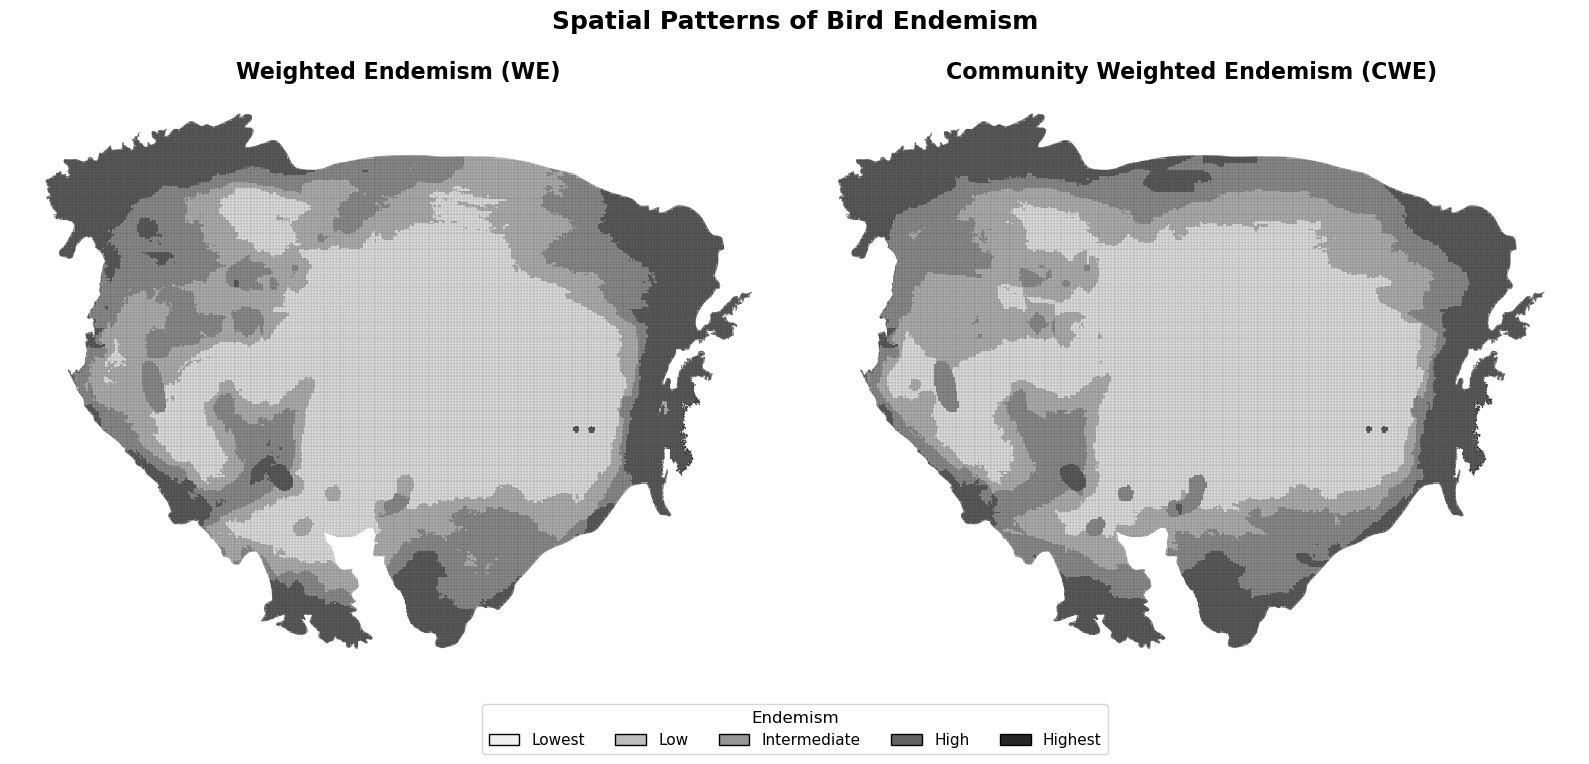

In [18]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# ---------------------------------------------------------
# 1. Define the five endemism categories
# ---------------------------------------------------------

labels = [
    "Lowest",
    "Low",
    "Intermediate",
    "High",
    "Highest"
]

# ---------------------------------------------------------
# 2. Classify WE and CWE using quintiles
# ---------------------------------------------------------

grid_bird_biodiversity["WE_class"] = pd.qcut(
    grid_bird_biodiversity["WE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

grid_bird_biodiversity["CWE_class"] = pd.qcut(
    grid_bird_biodiversity["CWE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

# ---------------------------------------------------------
# 3. Convert categories to numeric values
# ---------------------------------------------------------

class_values = {
    "Lowest": 1,
    "Low": 2,
    "Intermediate": 3,
    "High": 4,
    "Highest": 5
}

grid_bird_biodiversity["WE_class_num"] = grid_bird_biodiversity["WE_class"].map(class_values)
grid_bird_biodiversity["CWE_class_num"] = grid_bird_biodiversity["CWE_class"].map(class_values)

# ---------------------------------------------------------
# 4. Create figure
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8)
)

# Five discrete colours
cmap = ListedColormap([
    "#f0f0f0",   # Lowest
    "#bdbdbd",   # Low
    "#969696",   # Intermediate
    "#636363",   # High
    "#252525"    # Highest
])

# ---------------------------------------------------------
# 5. Weighted Endemism
# ---------------------------------------------------------

grid_bird_biodiversity.plot(
    column="WE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[0],
    vmin=1,
    vmax=5
)

axes[0].set_title(
    "Weighted Endemism (WE)",
    fontsize=16,
    fontweight="bold"
)

axes[0].axis("off")

# ---------------------------------------------------------
# 6. Corrected / Community Weighted Endemism
# ---------------------------------------------------------

grid_bird_biodiversity.plot(
    column="CWE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[1],
    vmin=1,
    vmax=5
)

axes[1].set_title(
    "Community Weighted Endemism (CWE)",
    fontsize=16,
    fontweight="bold"
)

axes[1].axis("off")

# ---------------------------------------------------------
# 7. Common legend
# ---------------------------------------------------------

from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=cmap(0), edgecolor="black", label="Lowest"),
    Patch(facecolor=cmap(1), edgecolor="black", label="Low"),
    Patch(facecolor=cmap(2), edgecolor="black", label="Intermediate"),
    Patch(facecolor=cmap(3), edgecolor="black", label="High"),
    Patch(facecolor=cmap(4), edgecolor="black", label="Highest")
]

fig.legend(
    handles=legend_elements,
    title="Endemism",
    loc="lower center",
    ncol=5,
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02)
)

# ---------------------------------------------------------
# 8. Overall figure
# ---------------------------------------------------------

plt.suptitle(
    "Spatial Patterns of Bird Endemism",
    fontsize=18,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.10, 1, 0.94])

# Save
plt.savefig(
    "bird_endemism_WE_CWE.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [19]:
grid_bird_biodiversity

,grid,weight_list,WE,richness,CWE,geometry,birds_species,WE_class,CWE_class,WE_class_num,CWE_class_num
0,308,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.026086,303,0.000086,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212...","[Gallinago media, Pandion haliaetus, Circus ae...",Highest,Highest,5,5
1,309,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.026058,303,0.000086,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538...","[Gallinago media, Pandion haliaetus, Circus ae...",Highest,Highest,5,5
2,318,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.028057,311,0.000090,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745...","[Circus macrourus, Gallinago media, Pandion ha...",Highest,Highest,5,5
3,319,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.028106,313,0.000090,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772...","[Circus macrourus, Gallinago media, Pandion ha...",Highest,Highest,5,5
4,320,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.028027,311,0.000090,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805...","[Circus macrourus, Gallinago media, Pandion ha...",Highest,Highest,5,5
...,...,...,...,...,...,...,...,...,...,...,...
114942,177138,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.185132,445,0.000416,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9...","[Accipiter brevipes, Buteo buteo, Circus macro...",Highest,Highest,5,5
114943,177503,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.134368,438,0.000307,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9...","[Accipiter brevipes, Buteo buteo, Circus macro...",Highest,Highest,5,5
114944,177504,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.191718,444,0.000432,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9...","[Accipiter brevipes, Buteo buteo, Circus macro...",Highest,Highest,5,5
114945,177505,"[9.482178245986667e-06, 8.719688183950543e-06,...",0.191347,443,0.000432,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0...","[Accipiter brevipes, Buteo buteo, Circus macro...",Highest,Highest,5,5
